# MLP desde cero (sin scikit-learn)

**Objetivo.** Implementar un Perceptrón Multicapa (MLP) usando únicamente NumPy —sin `scikit-learn` ni ningún framework de *deep learning*— para ver, en código, exactamente las ecuaciones de la presentación de la **Unidad 11 (Redes neuronales para clasificación)**.

**Qué cubre.** Forward pass, backpropagation y descenso de gradiente por mini-lotes, con la misma notación que se usó en la presentación:

$$
z^{(l)} = W^{(l)} a^{(l-1)} + b^{(l)}, \qquad a^{(l)} = f\!\left(z^{(l)}\right)
$$

$$
\delta^{(L)} = \nabla_{\mathbf a} L \odot f'\!\left(z^{(L)}\right), \qquad
\delta^{(l)} = \left(W^{(l+1)}\right)^{\!\top}\delta^{(l+1)} \odot f'\!\left(z^{(l)}\right)
$$

$$
\frac{\partial L}{\partial W^{(l)}} = \delta^{(l)}\left(a^{(l-1)}\right)^{\!\top}, \qquad
\frac{\partial L}{\partial b^{(l)}} = \delta^{(l)}
$$

**Demo.** Entrenamos la red sobre el problema **XOR** (diapositiva A2): el ejemplo clásico que un solo perceptrón **no puede** resolver, y que motiva por completo la necesidad de apilar capas (A3) y usar una activación no lineal (A5).

## 1. Funciones de activación

ReLU para las capas ocultas (B3) y sigmoide para la salida binaria (B2).

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def relu(z):
    return np.maximum(0, z)


def relu_deriv(z):
    return (z > 0).astype(z.dtype)


def sigmoid(z):
    z = np.clip(z, -500, 500)   # evita overflow en exp(-z)
    return 1.0 / (1.0 + np.exp(-z))

## 2. La clase `MLP`: forward, backward y entrenamiento

Admite cualquier número de capas ocultas (basta con cambiar `layer_sizes`). Cada ejemplo es una **columna** de la matriz `X`, por lo que `W[l]` tiene forma `(n_salida, n_entrada)` —igual que en las fórmulas de la presentación.

En `backward`, `delta` arranca en la capa de salida y se propaga hacia atrás multiplicando por `(W^(l))^T` y por la derivada local de la activación —exactamente la idea de la diapositiva C6 (reutilizar los factores ya calculados en vez de recalcular todo desde cero).

In [2]:
class MLP:
    """
    MLP totalmente conectado: ReLU en las capas ocultas, sigmoide en la
    salida (clasificación binaria), entrenado con entropía cruzada binaria.

    Parameters
    ----------
    layer_sizes : list[int]
        p. ej. [2, 4, 1]  ->  2 entradas, 4 neuronas ocultas, 1 salida.
    """

    def __init__(self, layer_sizes, seed=0):
        self.L = len(layer_sizes) - 1
        rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for l in range(self.L):
            n_in, n_out = layer_sizes[l], layer_sizes[l + 1]
            # inicialización "He": adecuada para ReLU
            self.W.append(rng.normal(0, np.sqrt(2.0 / n_in), size=(n_out, n_in)))
            self.b.append(np.zeros((n_out, 1)))

    def forward(self, X):
        """X: shape (n_features, n_samples) -- cada COLUMNA es un ejemplo."""
        a = X
        cache = {"a0": a}
        for l in range(self.L):
            z = self.W[l] @ a + self.b[l]
            a = relu(z) if l < self.L - 1 else sigmoid(z)
            cache[f"z{l+1}"], cache[f"a{l+1}"] = z, a
        self._cache = cache
        return a  # y_hat

    @staticmethod
    def loss(y_hat, y):
        eps = 1e-9
        y_hat = np.clip(y_hat, eps, 1 - eps)
        return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

    def backward(self, y):
        cache, m = self._cache, y.shape[1]
        grads_W, grads_b = [None] * self.L, [None] * self.L

        # delta^(L): para sigmoide + entropia cruzada binaria se simplifica a (y_hat - y)
        delta = cache[f"a{self.L}"] - y

        for l in range(self.L, 0, -1):
            a_prev = cache[f"a{l-1}"]
            grads_W[l - 1] = (delta @ a_prev.T) / m
            grads_b[l - 1] = np.sum(delta, axis=1, keepdims=True) / m
            if l > 1:
                delta = (self.W[l - 1].T @ delta) * relu_deriv(cache[f"z{l-1}"])

        return grads_W, grads_b

    def update(self, grads_W, grads_b, lr):
        for l in range(self.L):
            self.W[l] -= lr * grads_W[l]
            self.b[l] -= lr * grads_b[l]

    def fit(self, X, y, epochs=2000, lr=0.1, batch_size=None, verbose_every=200):
        n = X.shape[1]
        batch_size = batch_size or n
        rng = np.random.default_rng(42)
        history = []

        for epoch in range(1, epochs + 1):
            perm = rng.permutation(n)
            X_shuf, y_shuf = X[:, perm], y[:, perm]
            for start in range(0, n, batch_size):
                end = start + batch_size
                self.forward(X_shuf[:, start:end])
                grads_W, grads_b = self.backward(y_shuf[:, start:end])
                self.update(grads_W, grads_b, lr)

            epoch_loss = self.loss(self.forward(X), y)
            history.append(epoch_loss)
            if verbose_every and epoch % verbose_every == 0:
                print(f"época {epoch:5d}  |  pérdida = {epoch_loss:.4f}  |  exactitud = {self.accuracy(X, y):.2%}")

        return history

    def predict(self, X):
        return (self.forward(X) >= 0.5).astype(int)

    def accuracy(self, X, y):
        return np.mean(self.predict(X) == y)

## 3. El problema XOR (diapositiva A2)

| $x_1$ | $x_2$ | XOR |
|:---:|:---:|:---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

No existe una línea recta que separe las clases 0 y 1 --- por eso un solo perceptrón no puede resolverlo (A2), pero una MLP con una capa oculta sí (A3, A6).

In [3]:
X = np.array([[0, 0, 1, 1],
              [0, 1, 0, 1]], dtype=float)
y = np.array([[0, 1, 1, 0]], dtype=float)

mlp = MLP(layer_sizes=[2, 4, 1], seed=0)

### Antes de entrenar

Con pesos aleatorios, la red todavía no ha aprendido nada --- las predicciones deberían rondar el 50%.

In [4]:
y_hat_inicial = mlp.forward(X)
print("Predicciones antes de entrenar:", np.round(y_hat_inicial, 3))
print(f"Exactitud antes de entrenar: {mlp.accuracy(X, y):.0%}")

Predicciones antes de entrenar: [[0.5   0.444 0.355 0.354]]
Exactitud antes de entrenar: 25%


### Entrenamiento

Mini-batch SGD (aquí, con batch completo ya que sólo hay 4 ejemplos) --- ver diapositivas C7/D4/D5.

In [5]:
history = mlp.fit(X, y, epochs=3000, lr=0.5, verbose_every=500)

época   500  |  pérdida = 0.0114  |  exactitud = 100.00%
época  1000  |  pérdida = 0.0046  |  exactitud = 100.00%
época  1500  |  pérdida = 0.0028  |  exactitud = 100.00%
época  2000  |  pérdida = 0.0020  |  exactitud = 100.00%
época  2500  |  pérdida = 0.0016  |  exactitud = 100.00%
época  3000  |  pérdida = 0.0013  |  exactitud = 100.00%


### Curva de pérdida

Compara con la diapositiva D9 (curvas de pérdida y diagnóstico de sobreajuste).

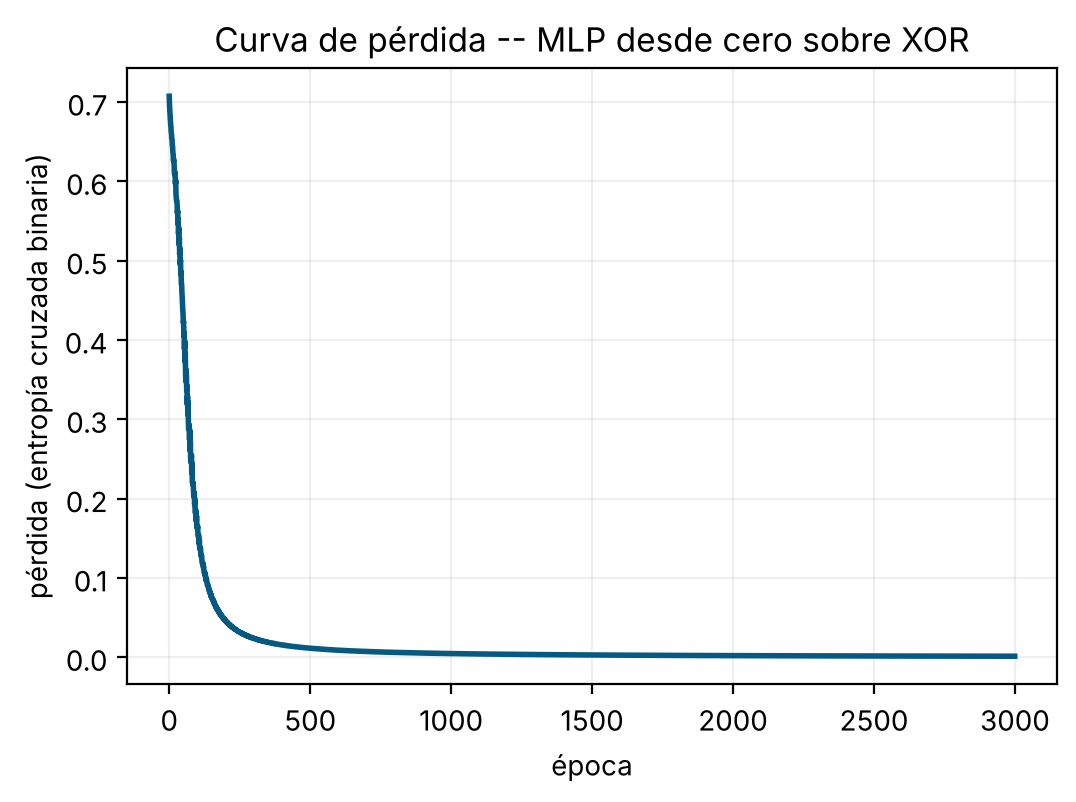

In [6]:
plt.figure(figsize=(6, 4))
plt.plot(history, color="#065A82", lw=2)
plt.xlabel("época")
plt.ylabel("pérdida (entropía cruzada binaria)")
plt.title("Curva de pérdida -- MLP desde cero sobre XOR")
plt.grid(alpha=0.2)
plt.show()

### Predicciones finales

In [7]:
y_hat = mlp.forward(X)
for i in range(X.shape[1]):
    x1, x2 = X[:, i]
    print(f"x = ({int(x1)}, {int(x2)})  ->  y_hat = {y_hat[0, i]:.4f}  "
          f"(predicción: {int(y_hat[0, i] >= 0.5)}, real: {int(y[0, i])})")

print(f"\nExactitud final: {mlp.accuracy(X, y):.0%}")

x = (0, 0)  ->  y_hat = 0.0036  (predicción: 0, real: 0)
x = (0, 1)  ->  y_hat = 0.9994  (predicción: 1, real: 1)
x = (1, 0)  ->  y_hat = 0.9994  (predicción: 1, real: 1)
x = (1, 1)  ->  y_hat = 0.0004  (predicción: 0, real: 0)

Exactitud final: 100%


## 4. Para explorar

- Cambia `layer_sizes=[2, 4, 1]` por `[2, 2, 1]` o `[2, 8, 1]`. ¿Sigue aprendiendo XOR con solo 2 neuronas ocultas?
- Prueba con un solo perceptrón (sin capa oculta, `layer_sizes=[2, 1]`) y comprueba que, como en A2, **no puede** resolver XOR por más que lo entrenes.
- Cambia el problema a AND u OR (sí son linealmente separables) y observa que incluso `layer_sizes=[2, 1]` los resuelve sin problema.
- Añade una segunda capa oculta (p. ej. `[2, 4, 4, 1]`) --- el mismo código de `backward` ya lo soporta, sin cambiar una sola línea (ver el ejemplo de C3 con dos capas ocultas).